<a href="https://colab.research.google.com/github/prabhleenkaursaini/UCS420/blob/main/Assignment7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [10]:
ROLL_NO = 1024170047          # <-- your full roll number
NAME = "Prabhleen Kaur Saini"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [11]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [12]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [13]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170047   Name: Prabhleen Kaur Saini   Fingerprint: 1CB63248   Tickets: 14

Ticket_ID                                                                            Ticket_Text
      T01                                                          Version 2.0.1 crashes at 99%.
      T02                                                  The Wi-Fi works, but the VPN doesn't.
      T03                                           The Python keeps disconnecting. Please help.
      T04                                              The LMS has stopped syncing. Please help.
      T05                   Python has stopped syncing on my laptop. I have tried several times!
      T06                                         The laptop stopped responding. This is urgent.
      T07  Python is showing an error when connected to campus Wi-Fi. I don't know what changed.
      T08                                           See https://lms.thapar.edu/help for details.
      T09                 LMS stopp

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [14]:
results = []
ticket_details = {}
for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    ticket_details[row["Ticket_ID"]] = result
    results.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })
preprocessing_table = pd.DataFrame(results)
total_row = {"Ticket_ID": "TOTAL"}
for column in preprocessing_table.columns[1:]:
    total_row[column] = preprocessing_table[column].sum()
preprocessing_table = pd.concat([preprocessing_table, pd.DataFrame([total_row])], ignore_index=True)
display(preprocessing_table)
selected_ticket = FOCUS[0]
selected_result = ticket_details[selected_ticket]
print("Selected ticket:", selected_ticket)
print(df.loc[df["Ticket_ID"] == selected_ticket, "Ticket_Text"].iloc[0])
print("\nActual tokens:", selected_result["tokens"])
print("Punctuation tokens:", selected_result["punct"])
print("Stopwords:", selected_result["stops"])
print("Final tokens:", selected_result["final"])

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,1,7,2,1,7,4
1,T02,1,10,2,4,9,4
2,T03,2,8,2,1,7,5
3,T04,2,9,2,2,8,5
4,T05,2,14,2,5,14,7
5,T06,2,9,2,3,8,4
6,T07,2,18,2,7,17,9
7,T08,1,7,2,1,7,4
8,T09,2,12,2,3,11,7
9,T10,2,17,2,7,16,8


Selected ticket: T09
LMS stopped responding after restarting the system. Please resolve it.

Actual tokens: ['lms', 'stopped', 'responding', 'after', 'restarting', 'the', 'system', '.', 'please', 'resolve', 'it', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['after', 'the', 'it']
Final tokens: ['lms', 'stopped', 'responding', 'restarting', 'system', 'please', 'resolve']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Tokens such as `n't`, `'s`, and `ca` can appear because `word_tokenize()` splits contractions into separate pieces. Since the preprocessing pipeline removes stopwords and punctuation but does not join contraction pieces back together, some fragments remain in the final tokens.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [15]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
import re
all_raw_texts = df["Ticket_Text"].tolist()
texts_to_check = all_raw_texts + TEST_LINES
patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"\b\d+(?:[.,]\d+)*(?:%?)\b",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with a vowel": r"\b[aeiouAEIOU][a-zA-Z]*\b"
}
for label, pattern in patterns.items():
    print("\n" + label)
    for i, text in enumerate(texts_to_check, start=1):
        print(f"Text {i}:", re.findall(pattern, text))
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"\b(?:https?://|www\.)[^\s<>]+"
phone_pattern = r"(?<!\w)(?:\+?\d{1,3}[- ]?)?(?:\(?\d{3,5}\)?[- ]?)?\d{3,5}[- ]?\d{3,5}(?!\w)"
def replace_contact_details(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, lambda m: m.group(0).rstrip(".,;!?") and "<URL>" + m.group(0)[len(m.group(0).rstrip(".,;!?")):] or "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text
print("\nReplacements on tickets and TEST_LINES:")
for i, text in enumerate(texts_to_check, start=1):
    print(f"Text {i}:", replace_contact_details(text))
capitalized_words = []
sentence_initial_capitalized = []
for text in all_raw_texts:
    capitalized_words.extend(re.findall(patterns["Capitalized words"], text))
    for sentence in re.split(r"(?<=[.!?])\s+", text):
        match = re.match(r"\s*([A-Z][a-zA-Z]*)", sentence)
        if match:
            sentence_initial_capitalized.append(match.group(1))
print("\nCapitalized word matches in tickets:", len(capitalized_words))
print("Sentence-initial capitalized words (occurrences):", len(sentence_initial_capitalized))
print("Sentence-initial matches:", sentence_initial_capitalized)


Words longer than 5 letters
Text 1: ['Version', 'crashes']
Text 2: []
Text 3: ['Python', 'disconnecting', 'Please']
Text 4: ['stopped', 'syncing', 'Please']
Text 5: ['Python', 'stopped', 'syncing', 'laptop', 'several']
Text 6: ['laptop', 'stopped', 'responding', 'urgent']
Text 7: ['Python', 'showing', 'connected', 'campus', 'changed']
Text 8: ['thapar', 'details']
Text 9: ['stopped', 'responding', 'restarting', 'system', 'Please', 'resolve']
Text 10: ['getting', 'logged', 'resetting', 'password', 'worked', 'yesterday']
Text 11: ['server', 'working', 'urgent']
Text 12: ['reinstalled', 'restarting', 'system', 'several']
Text 13: ['closed']
Text 14: ['Student', 'portal', 'disconnecting', 'during', 'another', 'computer']
Text 15: ['helpdesk', 'thapar', 'thapar', 'thapar']
Text 16: ['Version']
Text 17: []

Numbers
Text 1: ['2.0.1', '99']
Text 2: []
Text 3: []
Text 4: []
Text 5: []
Text 6: []
Text 7: []
Text 8: []
Text 9: []
Text 10: []
Text 11: []
Text 12: []
Text 13: ['3']
Text 14: []
Tex

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* The code above prints the number of sentence-initial capitalized-word occurrences. Some capitalized matches may also be proper nouns or acronyms, so sentence position alone does not prove that capitalization is only grammatical.


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [16]:
from nltk.tokenize import RegexpTokenizer
token_pattern = r"""https?://[^\s<>]+|www\.[^\s<>]+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d{1,3}(?:[- ]\d{3,5}){2,}|(?:\d{3,5}[- ]){1,2}\d{3,5}|\d+(?:\.\d+)+(?:%?)|\d+(?:,\d{3})+(?:\.\d+)?%?|[A-Za-z]+(?:['’][A-Za-z]+)+(?:-[A-Za-z]+(?:['’][A-Za-z]+)*)*|[A-Za-z]+(?:-[A-Za-z]+)+(?:['’][A-Za-z]+)*|[A-Za-z]+|[^\w\s]"""
custom_tokenizer = RegexpTokenizer(token_pattern)
def my_tokenize(text):
    return custom_tokenizer.tokenize(text)
print("Custom tokenization of TEST_LINES:")
for line in TEST_LINES:
    print("\nText:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))
comparison_rows = []
for _, row in df.iterrows():
    custom_tokens = my_tokenize(row["Ticket_Text"])
    standard_tokens = word_tokenize(row["Ticket_Text"])
    comparison_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Custom Count": len(custom_tokens),
        "word_tokenize Count": len(standard_tokens),
        "Different": custom_tokens != standard_tokens
    })
tokenizer_comparison = pd.DataFrame(comparison_rows)
display(tokenizer_comparison)
different_tickets = tokenizer_comparison.loc[tokenizer_comparison["Different"], "Ticket_ID"].tolist()
print("Tickets tokenized differently:", len(different_tickets), "out of", len(df))
print("Ticket IDs:", different_tickets)

Custom tokenization of TEST_LINES:

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p

,Ticket_ID,Custom Count,word_tokenize Count,Different
0,T01,6,7,True
1,T02,9,10,True
2,T03,8,8,False
3,T04,9,9,False
4,T05,14,14,False
5,T06,9,9,False
6,T07,17,18,True
7,T08,5,7,True
8,T09,12,12,False
9,T10,17,17,False


Tickets tokenized differently: 5 out of 14
Ticket IDs: ['T01', 'T02', 'T07', 'T08', 'T13']


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* The comparison table calculates the exact number for this roll-number-specific dataset and lists the ticket IDs that differ.


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [17]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
unique_final_tokens = sorted(set(token for result in ticket_details.values() for token in result["final"]))
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer("ing$", min=4)
lemmatizer = WordNetLemmatizer()
def penn_to_wordnet(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"
tagged_words = pos_tag(unique_final_tokens)
pos_map = {word: penn_to_wordnet(tag) for word, tag in tagged_words}
stemming_rows = []
for word in unique_final_tokens:
    outputs = {
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp (remove ing)": regexp_stemmer.stem(word),
        "POS Lemma": lemmatizer.lemmatize(word, pos_map[word])
    }
    if len(set(outputs.values())) > 1:
        stemming_rows.append(outputs)
stemming_table = pd.DataFrame(stemming_rows)
display(stemming_table)
print("Regexp rule: remove the suffix 'ing' from words ending in 'ing'.")
print("Dataset words supporting this choice:", [word for word in unique_final_tokens if word.endswith("ing")][:10])

,Word,Porter,Lancaster,Regexp (remove ing),POS Lemma
0,another,anoth,anoth,another,another
1,campus,campu,camp,campus,campus
2,changed,chang,chang,changed,change
3,closed,close,clos,closed,closed
4,computer,comput,comput,computer,computer
5,connected,connect,connect,connected,connect
6,crashes,crash,crash,crashes,crash
7,details,detail,detail,details,detail
8,disconnecting,disconnect,disconnect,disconnect,disconnect
9,error,error,er,error,error


Regexp rule: remove the suffix 'ing' from words ending in 'ing'.
Dataset words supporting this choice: ['disconnecting', 'getting', 'resetting', 'responding', 'restarting', 'showing', 'syncing', 'working']


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming occurs when a stemmer removes too much and produces a stem that no longer represents the intended word. Under-stemming occurs when related words remain with different stems. Use the differing rows in the table above to select examples from this generated dataset.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,159,83,0.522013
1,S2,130,76,0.584615
2,S3,79,53,0.670886
3,S4,79,50,0.632911


Top 10 words in S1:
[('.', 22), ('the', 12), ('i', 5), ('is', 5), ('stopped', 4), ('python', 3), ('please', 3), ('lms', 3), ('after', 3), ('it', 3)]

Top 10 words in S3:
[('stopped', 4), ('python', 3), ('please', 3), ('lms', 3), ('wi-fi', 2), ('works', 2), ('vpn', 2), ("n't", 2), ('keeps', 2), ('disconnecting', 2)]


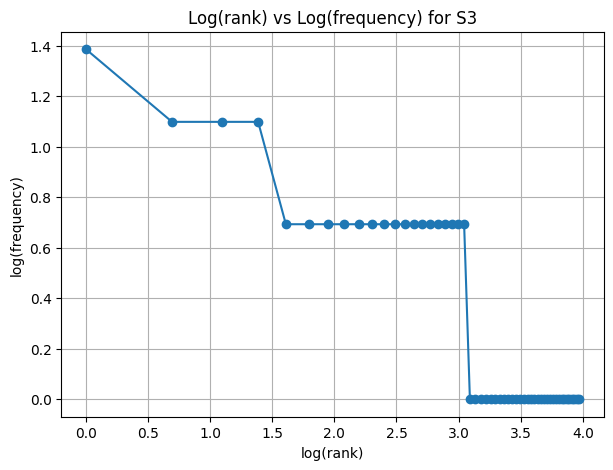

Top 5 bigrams in S1:
[(('.', 'i'), 5), (('.', 'the'), 4), (('.', 'please'), 3), (('the', 'vpn'), 2), (('keeps', 'disconnecting'), 2)]

Top 5 bigrams in S3:
[(('keeps', 'disconnecting'), 2), (('please', 'help'), 2), (('lms', 'stopped'), 2), (('stopped', 'syncing'), 2), (('tried', 'several'), 2)]


In [18]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from nltk.util import bigrams
S1 = [token.lower() for text in df["Ticket_Text"] for token in word_tokenize(text)]
S2 = [token for token in S1 if not is_punct(token)]
S3 = [token for result in ticket_details.values() for token in result["final"]]
S4 = [porter.stem(token) for token in S3]
corpora = {"S1": S1, "S2": S2, "S3": S3, "S4": S4}
statistics = []
for name, tokens in corpora.items():
    statistics.append({
        "Corpus": name,
        "Total Tokens": len(tokens),
        "Unique Tokens": len(set(tokens)),
        "TTR": len(set(tokens)) / len(tokens) if tokens else 0
    })
display(pd.DataFrame(statistics))
print("Top 10 words in S1:")
print(Counter(S1).most_common(10))
print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))
frequencies = Counter(S3)
ranked_frequencies = sorted(frequencies.values(), reverse=True)
ranks = np.arange(1, len(ranked_frequencies) + 1)
plt.figure(figsize=(7, 5))
plt.plot(np.log(ranks), np.log(ranked_frequencies), marker="o", linestyle="-")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log(rank) vs Log(frequency) for S3")
plt.grid(True)
plt.show()
print("Top 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))
print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR is the number of unique tokens divided by the total number of tokens. From S1 to S4, punctuation and stopwords are removed and the remaining words are Porter-stemmed. Removing frequent function words can increase the proportion of unique tokens, while stemming combines related word forms and can reduce it. The actual direction and size of the change depend on this generated dataset.


Give one example where word_tokenize() and your tokenizer differ. Explain the difference.

Answer: For the sentence "I can't connect to Wi-Fi." , word_tokenizer() may split "can't" into "ca" and "n't" whereas my custom tokenizer preserves "can't" as one token.
This happens because the custom tokenizer uses a regular expression that explicitly preserves contractions.

Give one example where stemming produces an undesirable result.

For example, Porter stemming may convert "university" into "univers". This is undesirable because "univers" is not a meaningful English word. Stemming removes suffixes mechanically without ensuring that the resulting word is valid or retains the original meaning.

Give one example where POS-aware lemmatization preserves meaning better than stemming.

For example, the word "better", when used as an adjective, can be lemmatized to "good" using WordNet Lemmatizer with the adjective POS tag. Stemming may leave it as "better" or produce a form that does not represent the correct dictionary base word. POS-aware lemmatization uses grammatical information to identify the appropriate lemma.